## Cancelamento de clientes de telecomunicações: base de dados da IBM

### Sobre a base de dados

**Contexto:** Dados demográficos, serviços contratados, informações de conta e situação de cancelamento dos clientes de uma empresa fictícia de telecomunicações.

**Dados:** 7.043 clientes e 21 colunas na versão CSV.

**Fonte:** [Kaggle: cancelamento de clientes de telecomunicações](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

**Variável alvo:** `Churn`, com os valores originais `Yes` (sim) e `No` (não).

### Roteiro da análise

1. Integridade dos dados: tipos, valores ausentes, duplicatas e cardinalidade das variáveis categóricas.
2. Distribuição das classes da variável alvo e análise exploratória.
3. Pré-processamento em `Pipeline` e separação estratificada treino/teste.
4. Otimização com `GridSearchCV` e validação cruzada estratificada de cinco folds para Regressão Logística, Árvore de Decisão, Random Forest e MLP.
5. Seleção do Recall como métrica de referência, tanto entre hiperparâmetros como entre algoritmos.
6. Exibição de Recall, PR-AUC, Precision, F1, ROC-AUC, Accuracy, Balanced Accuracy e Specificity, com média e desvio-padrão na validação cruzada.
7. Avaliação final no conjunto de teste reservado, matriz de confusão e persistência do pipeline e dos metadados.

### Importações

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sys
from pathlib import Path
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
)
project_root = next(
    (
        path
        for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "src").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("Diretório 'src' não encontrado.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import RANDOM_STATE
from sklearn.model_selection import train_test_split

pd.set_option("display.float_format", "{:.2f}".format)
pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (10, 6)
# RANDOM_STATE = 42

### 1. Integridade dos dados

In [10]:
# Leitura de dados
from src.data import load_dataset, split_features_target


df = load_dataset(allow_download=True)

# Converter somente o tipo numérico
raw_total_charges = df["TotalCharges"].copy()
df["TotalCharges"] = pd.to_numeric(raw_total_charges, errors="coerce")
invalid_total_charges = (
    raw_total_charges.notna()
    & raw_total_charges.astype(str).str.strip().ne("")
    & df["TotalCharges"].isna()
)

print(f"Base de dados: {df.shape[0]} clientes e {df.shape[1]} colunas")
print(f"Linhas duplicadas: {df.duplicated().sum()}")
print(f"Identificadores duplicados: {df['customerID'].duplicated().sum()}")
print(f"TotalCharges inválidos (não vazios): {invalid_total_charges.sum()}")

schema_summary = pd.DataFrame(
    {"DataType": df.dtypes.astype(str), "NonNullCount": df.notna().sum()}
)
display(schema_summary)

missing_summary = pd.DataFrame(
    {"MissingCount": df.isna().sum(), "MissingPercent": df.isna().mean().mul(100)}
)
display(missing_summary[missing_summary["MissingCount"] > 0])

Base de dados: 7043 clientes e 21 colunas
Linhas duplicadas: 0
Identificadores duplicados: 0
TotalCharges inválidos (não vazios): 0


,DataType,NonNullCount
customerID,object,7043
gender,object,7043
SeniorCitizen,int64,7043
Partner,object,7043
Dependents,object,7043
tenure,int64,7043
PhoneService,object,7043
MultipleLines,object,7043
InternetService,object,7043
OnlineSecurity,object,7043


,MissingCount,MissingPercent
TotalCharges,11,0.16


#### Cardinalidade das variáveis categóricas

gender: ['Female', 'Male']
Partner: ['No', 'Yes']
Dependents: ['No', 'Yes']
PhoneService: ['No', 'Yes']
MultipleLines: ['No', 'No phone service', 'Yes']
InternetService: ['DSL', 'Fiber optic', 'No']
OnlineSecurity: ['No', 'No internet service', 'Yes']
OnlineBackup: ['No', 'No internet service', 'Yes']
DeviceProtection: ['No', 'No internet service', 'Yes']
TechSupport: ['No', 'No internet service', 'Yes']
StreamingTV: ['No', 'No internet service', 'Yes']
StreamingMovies: ['No', 'No internet service', 'Yes']
Contract: ['Month-to-month', 'One year', 'Two year']
PaperlessBilling: ['No', 'Yes']
PaymentMethod: ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
SeniorCitizen: [0, 1]


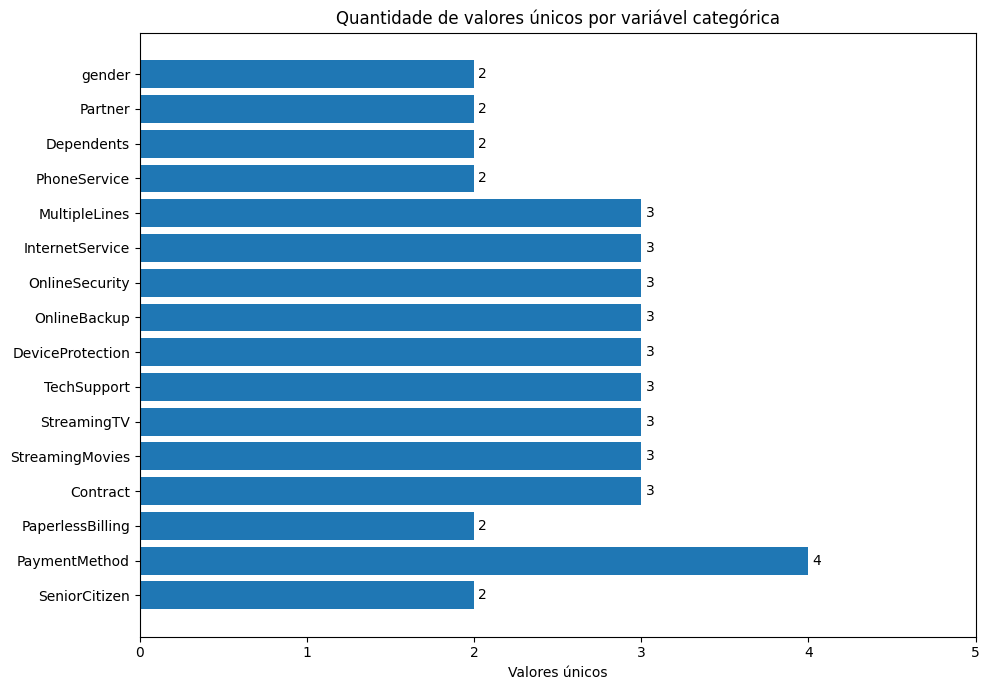

In [11]:
# A variável de pessoa idosa é uma categoria binária, embora armazenada como inteiro.
categorical_columns = [
    column
    for column in df.select_dtypes(include=["object", "string", "category"]).columns
    if column not in {"customerID", "Churn"}
]
categorical_columns.append("SeniorCitizen")

unique_counts = df[categorical_columns].nunique(dropna=False)
fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(unique_counts.index, unique_counts.values)
ax.bar_label(bars, padding=3)
ax.set_title("Quantidade de valores únicos por variável categórica")
ax.set_xlabel("Valores únicos")
ax.set_xlim(0, unique_counts.max() + 1)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.invert_yaxis()
plt.tight_layout()


for column in categorical_columns:
    values = sorted(df[column].dropna().unique().tolist(), key=str)
    print(f"{column}: {values}")

#### Interpretação das categorias

Os valores originais `No internet service` (sem serviço de internet) e `No phone service` (sem serviço telefônico) indicam clientes que não possuem o serviço correspondente. São categorias válidas, e não observações ausentes. A variável `SeniorCitizen` utiliza `0` e `1`.

### 2. Distribuição da variável alvo

,Churn,CustomerCount,Percent
0,No,5174,73.46
1,Yes,1869,26.54


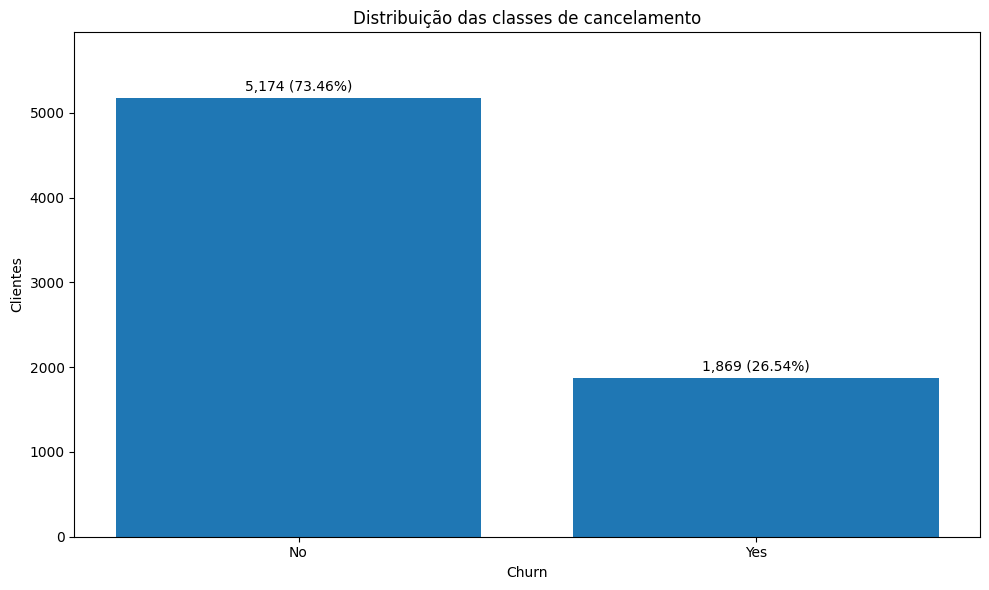

In [12]:
churn_values = (
    df.groupby("Churn", dropna=False).size().rename("CustomerCount").reset_index()
)
churn_values["Percent"] = churn_values["CustomerCount"].div(len(df)).mul(100).round(2)
display(churn_values)

fig, ax = plt.subplots()
bars = ax.bar(churn_values["Churn"], churn_values["CustomerCount"])
ax.bar_label(
    bars,
    labels=[
        f"{count:,} ({percent:.2f}%)"
        for count, percent in zip(
            churn_values["CustomerCount"], churn_values["Percent"]
        )
    ],
    padding=3,
)
ax.set_ylim(0, churn_values["CustomerCount"].max() * 1.15)
ax.set_xlabel("Churn")
ax.set_ylabel("Clientes")
ax.set_title("Distribuição das classes de cancelamento")
plt.tight_layout()

### 3. Distribuições das variáveis e relações numéricas

,OutlierCount
tenure,0
MonthlyCharges,0
TotalCharges,0


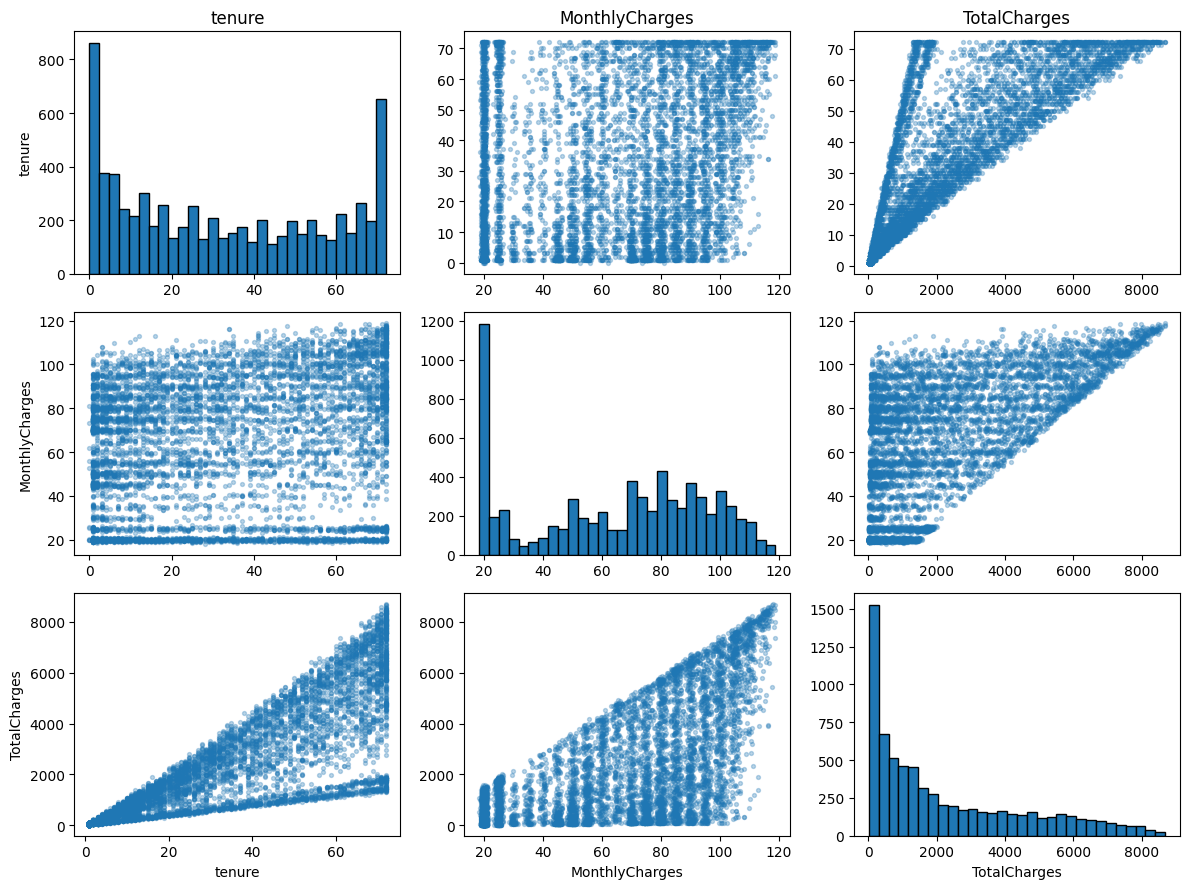

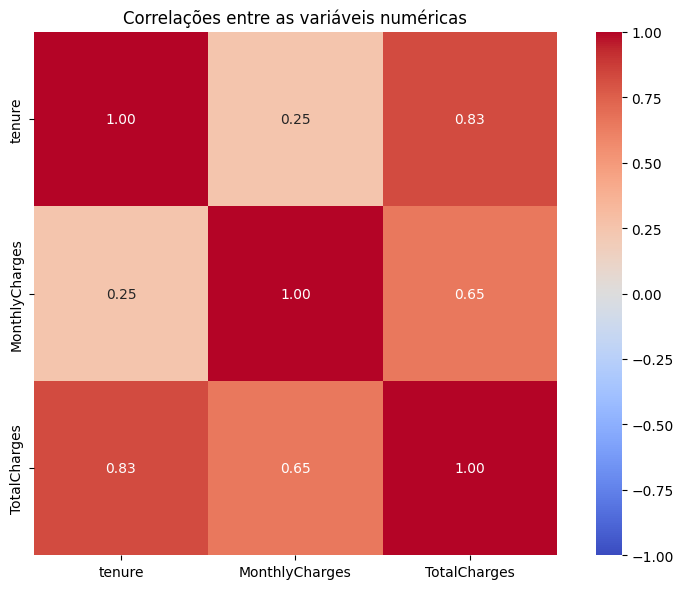

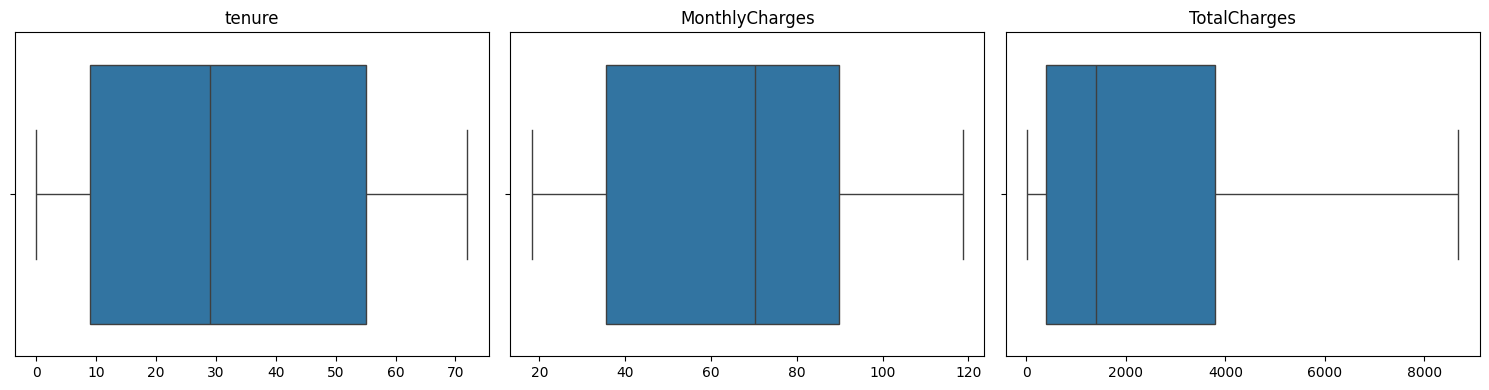

In [13]:
# Excluir a categoria demográfica binária da análise numérica contínua.
numeric_columns = [
    column
    for column in df.select_dtypes(include=np.number).columns
    if column != "SeniorCitizen"
]

n_columns = len(numeric_columns)
fig, axes = plt.subplots(
    n_columns, n_columns, figsize=(4 * n_columns, 3 * n_columns), squeeze=False
)
for row, y_column in enumerate(numeric_columns):
    for col, x_column in enumerate(numeric_columns):
        ax = axes[row, col]
        if row == col:
            ax.hist(df[x_column].dropna(), bins=30, edgecolor="black")
        else:
            pair = df[[x_column, y_column]].dropna()
            ax.scatter(pair[x_column], pair[y_column], alpha=0.3, s=8)
        if row == 0:
            ax.set_title(x_column)
        if col == 0:
            ax.set_ylabel(y_column)
        if row == n_columns - 1:
            ax.set_xlabel(x_column)
plt.tight_layout()

correlation_matrix = df[numeric_columns].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
)
plt.title("Correlações entre as variáveis numéricas")
plt.tight_layout()

fig, axes = plt.subplots(1, n_columns, figsize=(5 * n_columns, 4), squeeze=False)
for ax, column in zip(axes.flat, numeric_columns):
    sns.boxplot(x=df[column], ax=ax)
    ax.set_title(column)
    ax.set_xlabel("")
plt.tight_layout()

# Contar observações fora dos limites de 1,5 vez a amplitude interquartil.
quartiles = df[numeric_columns].quantile([0.25, 0.75])
iqr = quartiles.loc[0.75] - quartiles.loc[0.25]
outlier_counts = (
    df[numeric_columns].lt(quartiles.loc[0.25] - 1.5 * iqr)
    | df[numeric_columns].gt(quartiles.loc[0.75] + 1.5 * iqr)
).sum()
display(outlier_counts.rename("OutlierCount").to_frame())

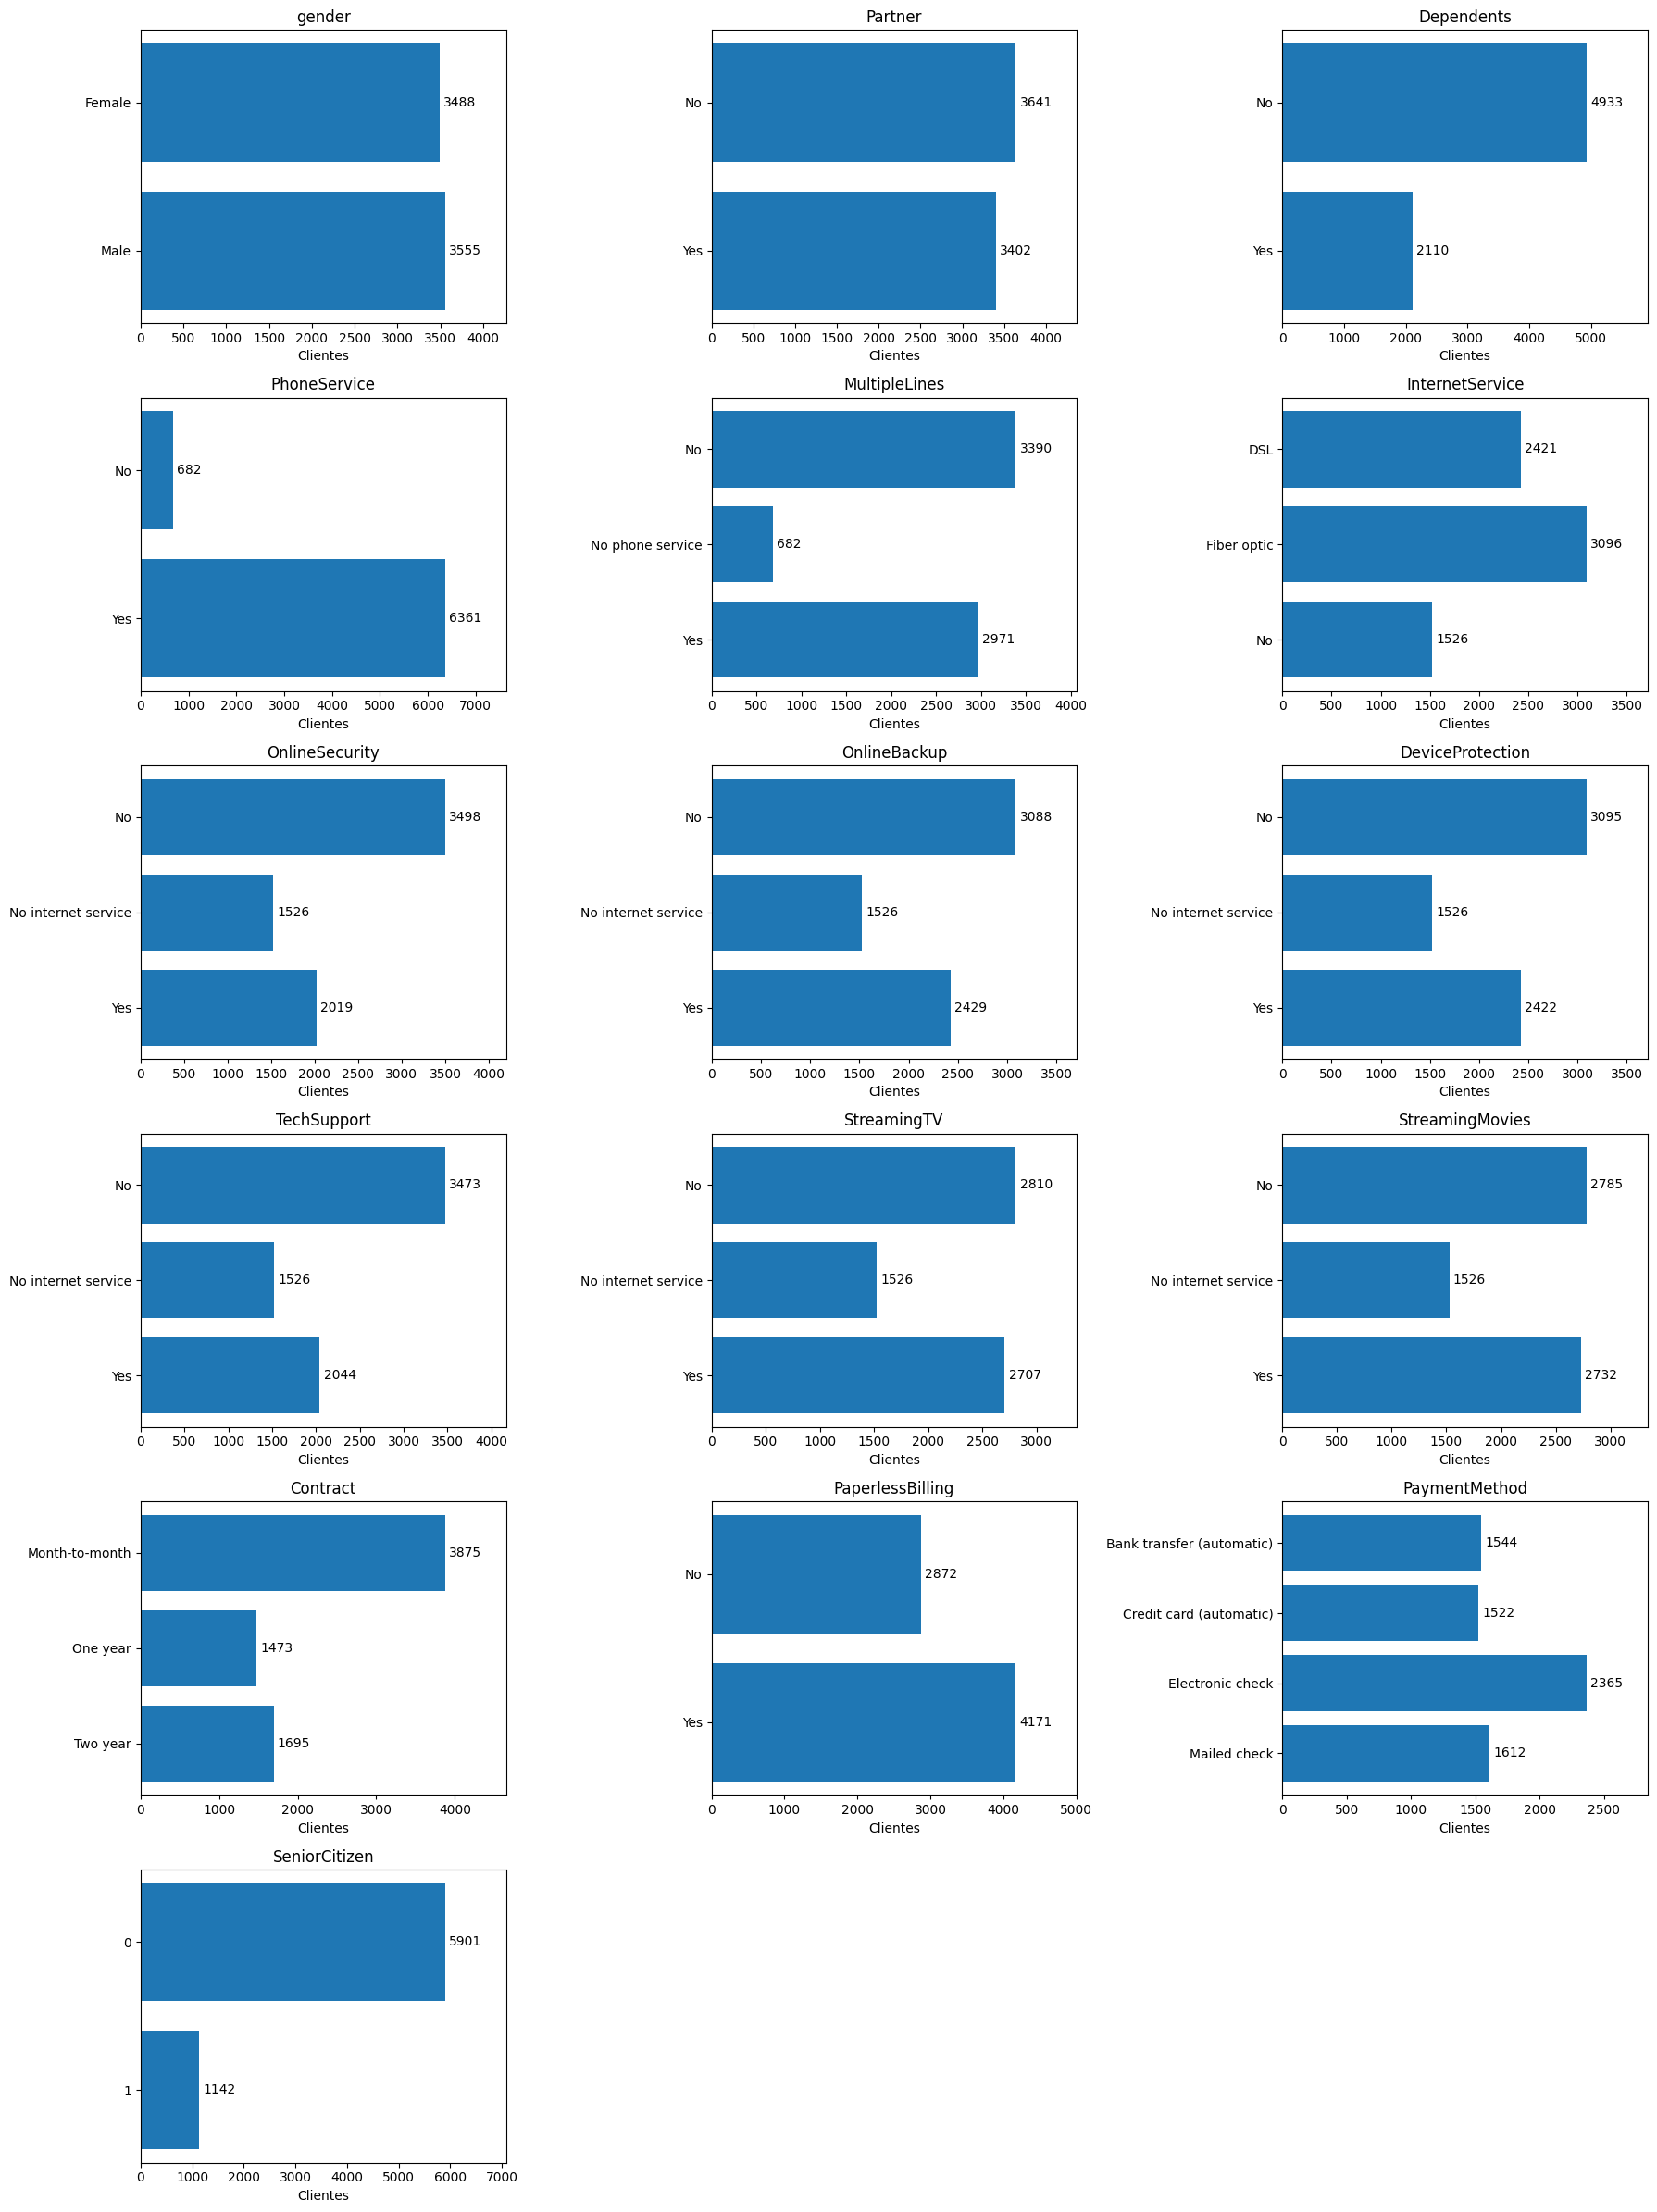

In [14]:
n_plot_columns = 3
n_plot_rows = (len(categorical_columns) + n_plot_columns - 1) // n_plot_columns
fig, axes = plt.subplots(
    n_plot_rows,
    n_plot_columns,
    figsize=(18, 4 * n_plot_rows),
    squeeze=False,
)
for ax, column in zip(axes.flat, categorical_columns):
    counts = df[column].value_counts(dropna=False).sort_index()
    bars = ax.barh(
        [str(value) for value in counts.index],
        counts.values,
    )
    ax.bar_label(bars, padding=3)
    ax.set_title(column)
    ax.set_xlabel("Clientes")
    ax.set_xlim(0, counts.max() * 1.2)
    ax.invert_yaxis()
for ax in list(axes.flat)[len(categorical_columns) :]:
    ax.set_visible(False)
plt.tight_layout()

### 4. Pré-processamento e separação dos dados

A imputação, a codificação e a padronização são ajustadas exclusivamente nos dados de treinamento de cada partição, evitando vazamento de dados.

In [15]:
from src.preprocessing import build_preprocessor, prepare_features


X, y, feature_columns = split_features_target(df)

if y.isna().any():
    raise ValueError("A variável Churn contém categorias inesperadas.")

y = y.astype(int)
X = prepare_features(X)

preprocessor = build_preprocessor(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Treinamento: {len(X_train)} | Teste: {len(X_test)}")
print(f"Proporção de Churn=Yes no treino: {y_train.mean():.2%}")

Treinamento: 5634 | Teste: 1409
Proporção de Churn=Yes no treino: 26.54%


### 5–7. Otimização, validação cruzada e comparação

São usados os mesmos cinco folds estratificados para comparar os quatro algoritmos. Cada transformação é ajustada exclusivamente no treino de seu respectivo fold, prevenindo vazamento.

A função de seleção do `GridSearchCV` implementa **ordenação lexicográfica**: maior `mean_test_recall` primeiro; em caso de empate exato, maior `mean_test_average_precision`. O mesmo desempate é aplicado à comparação global dos modelos. A PR-AUC é calculada por `average_precision` (Average Precision do scikit-learn, não integração trapezoidal).

In [16]:
from src.models import build_estimators, build_param_grids
from src.models import train_and_evaluate_models

models = build_estimators(RANDOM_STATE)
param_grids = build_param_grids()

# Executando o treinamento e busca de hiperparâmetros
searches, comparison_df = train_and_evaluate_models(
    models=models,
    param_grids=param_grids,
    preprocessor=preprocessor,
    X_train=X_train,
    y_train=y_train
)

# Exibindo os resultados formatados no notebook
display(comparison_df.round(4))

LogisticRegression: Recall = 0.8013; PR-AUC = 0.6600; parâmetros = {'model__C': 1.0, 'model__class_weight': 'balanced'}


,Model,BestParams,recall_mean,recall_std,average_precision_mean,average_precision_std,precision_mean,precision_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std
0,RandomForest,"{'model__class_weight': 'balanced', 'model__ma...",0.81,0.03,0.65,0.01,0.50,0.01,0.62,0.01,0.84,0.01,0.74,0.01,0.76,0.01
1,LogisticRegression,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.80,0.04,0.66,0.02,0.52,0.02,0.63,0.02,0.85,0.01,0.75,0.02,0.77,0.02
2,DecisionTree,"{'model__class_weight': 'balanced', 'model__ma...",0.79,0.06,0.60,0.02,0.49,0.02,0.60,0.01,0.83,0.01,0.72,0.02,0.75,0.01
3,MLPClassifier,"{'model__alpha': 0.001, 'model__hidden_layer_s...",0.56,0.06,0.65,0.02,0.66,0.03,0.60,0.03,0.84,0.01,0.80,0.01,0.72,0.02


### 8. Seleção do modelo e avaliação final

O modelo vencedor é escolhido pela **maior média de Recall na validação cruzada**.

Modelo selecionado por Recall: RandomForest
Melhores hiperparâmetros: {'model__class_weight': 'balanced', 'model__max_depth': 4, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 16, 'model__n_estimators': 200}


,Metric,TestScore
0,recall,0.78
1,average_precision,0.64
2,precision,0.48
3,f1,0.60
4,roc_auc,0.84
5,accuracy,0.72
6,balanced_accuracy,0.74


Relatório por classe:
              precision    recall  f1-score   support

          No       0.90      0.69      0.78      1035
         Yes       0.48      0.78      0.60       374

    accuracy                           0.72      1409
   macro avg       0.69      0.74      0.69      1409
weighted avg       0.79      0.72      0.73      1409



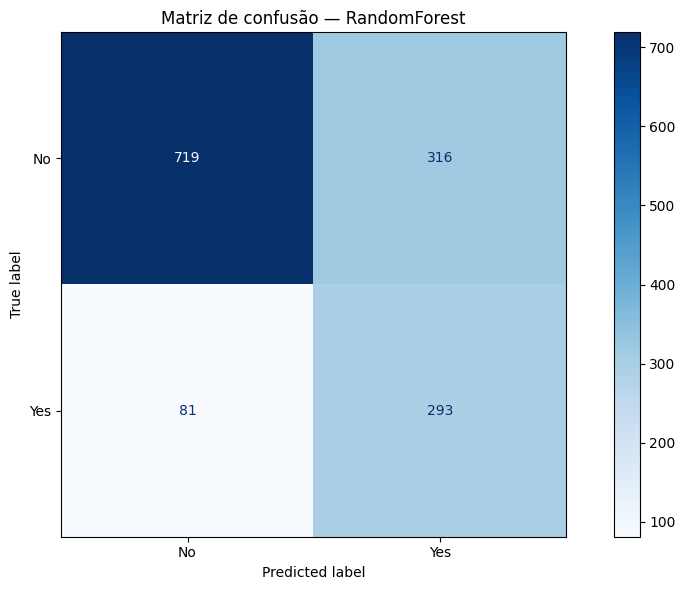

In [17]:
from src.evaluate import avaliar_modelo_final
from src.training import select_champion

best_model_name, best_pipeline = select_champion(
    comparison_df,
    searches,
)
test_metrics = avaliar_modelo_final(best_pipeline, X_test, y_test)
y_pred = best_pipeline.predict(X_test)

test_recall = test_metrics["recall"]
test_average_precision = test_metrics["average_precision"]

print(f"Modelo selecionado por Recall: {best_model_name}")
print(f"Melhores hiperparâmetros: {searches[best_model_name].best_params_}")

test_results_df = pd.DataFrame(
    {"Metric": list(test_metrics.keys()), "TestScore": list(test_metrics.values())}
)

display(test_results_df.round(4))
print("Relatório por classe:")
print(classification_report(y_test, y_pred, target_names=["No", "Yes"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0, 1], display_labels=["No", "Yes"], cmap="Blues"
)

plt.title(f"Matriz de confusão — {best_model_name}")
plt.tight_layout()

### 9. Registro dos experimentos e persistência

São salvos o pipeline vencedor (`joblib`), os resultados de validação cruzada dos quatro algoritmos (`csv`) e os metadados do experimento (`json`).

In [18]:
from src.artifacts import build_experiment_metadata, save_training_artifacts
from src.config import COMPARISON_PATH, CV_FOLDS, DATASET_PATH, EXPERIMENT_PATH, MODEL_PATH

experiment_metadata = build_experiment_metadata(
    dataset_name=DATASET_PATH.name,
    best_model_name=best_model_name,
    best_params=searches[best_model_name].best_params_,
    test_metrics=test_metrics,
    feature_columns=feature_columns,
    random_state=RANDOM_STATE,
    test_size=0.20,
    cv_folds=CV_FOLDS,
)

save_training_artifacts(
    model=best_pipeline,
    comparison_df=comparison_df,
    metadata=experiment_metadata,
    model_path=MODEL_PATH,
    comparison_path=COMPARISON_PATH,
    metadata_path=EXPERIMENT_PATH,
)

print(f"Modelo: {MODEL_PATH}")
print(f"Comparação: {COMPARISON_PATH}")
print(f"Metadados: {EXPERIMENT_PATH}")

Modelo: C:\felipe\fiap\projeto-fase-1\pos-tech-challenge-fase1\models\telco_churn_best_model.joblib
Comparação: C:\felipe\fiap\projeto-fase-1\pos-tech-challenge-fase1\models\telco_churn_model_comparison.csv
Metadados: C:\felipe\fiap\projeto-fase-1\pos-tech-challenge-fase1\models\telco_churn_experiment.json
